# Stage 04 — Text Representations

## Objective

Compare six document representations for the four E-commerce categories: unigram BoW,
unigram TF-IDF, cumulative unigram/bigram and unigram/bigram/trigram TF-IDF, TRAIN-fitted
Word2Vec document means, and frozen `sentence-transformers/all-MiniLM-L6-v2` embeddings.
The questions are distinct: **storage**, **same/different-category similarity**, **category
geometry**, **unsupervised clusters**, and **fold-clean supervised classification**.

The [official assignment](https://hcmus-cs-ta.github.io/lab-book/data-mining/projects/preprocessing/)
requires dimensions/sparsity, cosine, t-SNE and silhouette. It labels Sentence Transformer
“advanced”, while its scoring table explicitly names Sentence Transformer; therefore this
chapter also implements K-Means and Linear SVM comparisons. The general library list omits
gensim although Word2Vec is explicitly required. We disclose using standard gensim with an exact numerical-correctness source fix
rather than silently omitting Word2Vec or claiming instructor approval of that interpretation.
The project environment remains Python 3.13.3 with earlier package pins preserved.

Read [Stage 01](01_eda.ipynb), [Stage 02](02_normalization_tokenization.ipynb) and
[Stage 03](03_stopwords_morphology.ipynb) for earlier evidence. This chapter independently
reads raw data; it never executes those notebooks or reuses their classifier scores.

## Methodology

**Frozen population/input.** Recreate `make_text_protocol(raw, test_size=.2, seed=42)`.
Canonical deduplication changes the unit from listing occurrence to first eligible canonical
text; it does not remove every product variant. Keep original labels, strings and CSV-record
`row_id`s. Reuse Stage 02 default normalization, retaining numbers, followed by Stage 03's
lowercase Unicode lexical tokenizer. Use **space-joined lexical tokens as the exact common
text** for all representations (Word2Vec receives the equivalent token lists). Stopwords stay;
no stemming/lemmatization is selected from observed Stage 03 results. Punctuation-separated
codes are fragmented by this already declared lexical definition; `@home` loss in the fixed
normalizer remains a known risk. Sentence embeddings receive this same punctuation-reduced
input, which may differ from their natural-sentence pretraining domain.

**Three separate fitting scopes.**

| Analysis | Fitting scope | Evaluation scope |
|---|---|---|
| Dimensions, cosine and descriptive geometry | All TRAIN; no assessment text | TRAIN pairs / fixed bounded TRAIN subset |
| Sparse Linear SVM CV | New vocabulary/IDF and SVM inside each fitting fold | Its validation rows only |
| Frozen MiniLM Linear SVM CV | Public pretrained encoder fixed; SVM inside each fitting fold | Its validation rows only |

Recreate the exact Stage 03 normalized-base five group folds, shuffle/seed 42, and verify
membership fingerprints. All learned CV state is fold-local. Full-TRAIN Word2Vec is used
**only for descriptive representation analysis**; no globally trained Word2Vec CV score is
reported. The frozen label-free encoder may process TRAIN before CV because it fits no
corpus parameters. No scaler learns from validation; each row uses stateless L2 normalization.

**Predeclared settings.** Sparse features use `min_df=2`, `max_features=30000`, built-in word
analyzer with `str.split`, no second lowercasing/regex, and n-gram ranges `(1,1)`, `(1,2)`,
`(1,3)`. A callable analyzer would bypass n-grams, so it is intentionally avoided. All five
SVM variants use C=1, squared hinge, primal LinearSVC, seed 42, max_iter=10000, tol=1e-4.
No grid search, new outer split, assessment scoring or representation selection on assessment.

For descriptive cosine, draw 600 unique unordered non-self pairs per category and 400 per
unordered category pair: **2,400 same / 2,400 different**. Every representation uses the exact
same pair IDs. For geometry, sample 300 TRAIN rows per category, seed 42 (1,200 total): equal
class weights intentionally differ from original prevalence. Use the intersection of nonzero
rows across representations for all geometric comparisons, report any exclusions, and retain
all original rows in matrices/CV. Cosine with a zero vector is defined as 0 for pair summaries;
its geometric interpretation is limited and zero-pair counts are disclosed.

**Geometric conventions.** L2-normalize document rows. Main silhouettes use cosine distance
in the **original representation space**, separately for true labels and K-Means assignments;
Euclidean silhouettes are a declared sensitivity. Ordinary Euclidean K-Means uses K=4,
k-means++, 10 starts, seed 42, max_iter=300 on the same unit vectors. It is not spherical
K-Means; centroids need not remain unit length. ARI is supporting agreement evidence only.
For t-SNE only, fit TruncatedSVD(50, n_iter=7, seed=42) on each representation's common subset,
renormalize and use Euclidean t-SNE(2), perplexity=30, init=PCA, learning_rate=auto,
max_iter=1000, seed=42. Neither silhouette nor classifier uses the 2D coordinates.

All source rows informed earlier EDA. The untouched-in-this-stage outer partition remains an
**internal post-EDA assessment**, not an independent external cohort. Group equality does
not eliminate near-duplicate/family dependence. Shared-fold sample SD is descriptive, not a
confidence interval or significance test.

## Implementation

Run all cells with a fresh existing `hcmus-wids` `.venv` kernel from root or `book/text/`.
Pure metrics/factories in `src/text_representations.py` keep the main experiments visible
here and permit small known-answer tests. The existing source/split/normalization helpers
are unchanged. Raw data must be at `data/raw/ecommerce/ecommerceDataset.csv`; see README.

Only public frozen model files are downloaded to ignored `.cache/huggingface/`, at an exact
revision. No token, downloaded weights, full corpus, fitted document cache or processed matrix
is exported to Git. The model loader first tries that local revision; if missing, it downloads
only the required files. Download failure raises an actionable error, with no substitute
embedding. Saved notebook outputs support static builds without raw data, model download,
model cache, Kaggle credentials or GPU.

In [1]:
from pathlib import Path
from collections import Counter
from importlib.metadata import version, distribution
from time import perf_counter
import hashlib
import html
import json
import os
import platform
import re
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE
from sklearn.metrics import f1_score, accuracy_score, adjusted_rand_score
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits
from IPython.display import display, HTML
from gensim.models import Word2Vec
import torch
from sentence_transformers import SentenceTransformer
from huggingface_hub import snapshot_download
from huggingface_hub.utils import disable_progress_bars
from transformers.utils import logging as transformers_logging

ROOT=next((p for p in (Path.cwd(),*Path.cwd().parents)
           if (p/"myst.yml").is_file() and (p/"src/text_representations.py").is_file()),None)
if ROOT is None: raise RuntimeError("Start inside this repository.")
if Path(sys.prefix).resolve()!=(ROOT/".venv").resolve():
    raise RuntimeError("Select the project's existing .venv kernel (hcmus-wids), restart and Run All.")
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.text_data import LABELS, read_ecommerce, make_text_protocol
from src.text_preprocessing import normalize_default, lexical_tokens
from src.text_representations import (fixed_text_folds, word_vectorizer, sparse_svm_pipeline,
    linear_svm, matrix_profile, row_norms, paired_cosines, sample_document_pairs, balanced_subset,
    stable_word_hash, mean_word_vectors, frozen_sentence_vectors, safe_silhouette, word2vec_numeric_guard)
SEED=42
DATA_PATH=ROOT/"data/raw/ecommerce/ecommerceDataset.csv"
MODEL_NAME="sentence-transformers/all-MiniLM-L6-v2"
MODEL_REVISION="1110a243fdf4706b3f48f1d95db1a4f5529b4d41"
MODEL_CACHE=ROOT/".cache/huggingface"
MODEL_FILES=["config.json","modules.json","config_sentence_transformers.json","sentence_bert_config.json",
             "tokenizer.json","tokenizer_config.json","special_tokens_map.json","vocab.txt",
             "model.safetensors","1_Pooling/config.json"]
SPARSE_CONFIGS={"BoW":(False,1),"TF-IDF 1":(True,1),"TF-IDF 1-2":(True,2),"TF-IDF 1-3":(True,3)}
MAX_FEATURES=30000
MIN_DF=2
PAIR_SEED=SUBSET_SEED=42
PER_CLASS=300
W2V_PARAMETERS=dict(vector_size=100,window=5,min_count=2,sg=0,cbow_mean=1,negative=5,hs=0,
                    sample=1e-3,epochs=10,workers=1,seed=42,sorted_vocab=1,hashfxn=stable_word_hash)
torch.set_num_threads(4);torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True)
disable_progress_bars();transformers_logging.disable_progress_bar()
sns.set_theme(style="whitegrid",context="notebook")
plt.rcParams.update({"figure.dpi":110,"savefig.dpi":140})

def prose(text):
    safe=html.escape(text)
    return HTML("<p>"+re.sub(r"\*\*(.+?)\*\*",r"<strong>\1</strong>",safe)+"</p>")

def show_table(frame,title=None,collapse=False,**kwargs):
    body='<div style="overflow-x:auto">'+frame.to_html(escape=True,**kwargs)+'</div>'
    if collapse: body=f"<details><summary>{html.escape(title or 'Supporting table')}</summary>{body}</details>"
    elif title: body=f"<p><strong>{html.escape(title)}</strong></p>"+body
    display(HTML(body))

print("Python",platform.python_version(),"|",platform.system(),platform.machine(),"| CPU only; torch threads=4, BLAS=2")
packages=["numpy","scipy","scikit-learn","gensim","sentence-transformers","torch","transformers","tokenizers"]
show_table(pd.DataFrame({"package":packages,"version":[version(p) for p in packages]}),index=False)

/Users/nguyenduchung/data-mining-preprocessing/data-mining-preprocessing/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1116 21:36:35.855000 87573 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Python 3.13.3 | Darwin arm64 | CPU only; torch threads=4, BLAS=2


package,version
numpy,2.5.4
scipy,1.18.1
scikit-learn,1.9.1
gensim,4.4.0
sentence-transformers,6.3.0
torch,2.15.0
transformers,5.23.0
tokenizers,0.23.3


In [2]:
if not DATA_PATH.is_file():
    raise FileNotFoundError("Place the original Kaggle ecommerceDataset.csv in data/raw/ecommerce/; see README.")
raw_sha256_before=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
raw=read_ecommerce(DATA_PATH);raw_snapshot=raw.copy(deep=True)
protocol=make_text_protocol(raw,test_size=.2,seed=42)
train=protocol["train"].copy();assessment_ids=protocol["test"].row_id.copy()
observed_fingerprints={"source":raw_sha256_before,
    "train":hashlib.sha256(train.row_id.to_numpy(dtype="<i8").tobytes()).hexdigest(),
    "assessment":hashlib.sha256(assessment_ids.to_numpy(dtype="<i8").tobytes()).hexdigest()}
REFERENCES={"source":"1d44be1780bc9558f40ab4cee5b32051ddfe90647cd525b9652b47cdb233593f",
    "train":"b36f8f64739c881a5beb35e57b0a5068f3a319733506aca0b34a89ccdac0fe2c",
    "assessment":"737d4fab65e776bce15718b1e512546b547a6bc53802d7f3228933293084cce6"}
fingerprint_table=pd.DataFrame({"observed":observed_fingerprints,"Stage02_03_reference":REFERENCES})
fingerprint_table["matches"]=fingerprint_table.observed.eq(fingerprint_table.Stage02_03_reference)
assert fingerprint_table.matches.all(),"Source/protocol difference: investigate, never force reference counts."
assert set(train.row_id).isdisjoint(assessment_ids)
assert set(train.canonical_key).isdisjoint(protocol["test"].canonical_key)
base_text=train.text.map(normalize_default)
base_tokens=base_text.map(lexical_tokens)
input_text=base_tokens.map(" ".join)
y=train.label.to_numpy()
folds,group_ids=fixed_text_folds(y,base_text,seed=42)
# References are Stage 03's saved validation-row fingerprints, not scores or substituted counts.
STAGE03_FOLD_REFERENCES=['a0591b021b54dbb038950b5ee958c7a4471d42e158362b9311671606902d55a8', '29eddd5cb4f05d942fd02db71d26816bf9b737b07c6ea19ffce6028aee5833e8', '042b87ae65a87a38063834f441bad3ee6bf4905a6c793a083b16479954c1fcc4', 'e26601929e364bf80de2fec02d4f1904111b5c4d4cd040f8ae68c40bf6c344ed', '758b4dffa158c7c4276489eb83fb8c73de16a636a7820cd2002825b01249dc7f']
fold_records=[];fold_support=[];validation_coverage=np.zeros(len(train),dtype=int)
for number,(fitting,validation) in enumerate(folds,1):
    overlap=len(set(group_ids[fitting])&set(group_ids[validation]))
    digest=hashlib.sha256(np.sort(train.iloc[validation].row_id.to_numpy(dtype="<i8")).tobytes()).hexdigest()
    assert overlap==0 and set(fitting).isdisjoint(validation)
    assert digest==STAGE03_FOLD_REFERENCES[number-1]
    assert set(y[fitting])==set(LABELS) and set(y[validation])==set(LABELS)
    validation_coverage[validation]+=1
    fold_records.append({"fold":number,"fitting_N":len(fitting),"validation_N":len(validation),
                         "group_overlap":overlap,"validation_ID_SHA256":digest})
    for label in LABELS:
        fold_support.append({"fold":number,"label":label,"fit_N":int((y[fitting]==label).sum()),
                             "validation_N":int((y[validation]==label).sum())})
assert np.all(validation_coverage==1)
fold_table=pd.DataFrame(fold_records)
normalized_group_counts=base_text.value_counts()
protocol_measurements=pd.Series({"raw_N":len(raw),"canonical_eligible_N":len(protocol["corpus"]),
    "TRAIN_N":len(train),"assessment_N":len(assessment_ids),"normalized_duplicate_groups":int(normalized_group_counts.ge(2).sum()),
    "normalized_redundant_rows":int((normalized_group_counts-1).sum()),
    "empty_common_inputs":int(input_text.eq("").sum()),"lexical_types":len(set(t for tokens in base_tokens for t in tokens))},name="measured")

## Results

### Source, frozen folds and analysis scope

The following values are recomputed from raw. Source and outer membership match Stage 02/03,
and all five validation membership hashes match Stage 03 exactly. The assessment contributes
only IDs/keys to boundary checks and is not embedded or classified. No earlier score is reused.
Single-character and numeric lexical tokens remain eligible; corpus frequency thresholds and
feature caps are separate representation choices, not silent changes to the input text.

In [3]:
show_table(protocol_measurements.to_frame())
show_table(fingerprint_table[["matches"]],"Source and outer membership checks")
show_table(fingerprint_table,"Full source/partition fingerprints",collapse=True)
class_support=train.label.value_counts().reindex(LABELS).rename("TRAIN_N").to_frame()
class_support["TRAIN_pct"]=100*class_support.TRAIN_N/len(train)
show_table(class_support.round(3))
show_table(fold_table.drop(columns="validation_ID_SHA256"),"Exact Stage 03 folds",index=False)
show_table(pd.DataFrame(fold_support),"Class support in every fitting/validation fold",collapse=True,index=False)
show_table(fold_table[["fold","validation_ID_SHA256"]],"Stage 03 matching fold fingerprints",collapse=True,index=False)
display(prose(f"**Measured:** {len(raw):,} raw rows → {len(protocol['corpus']):,} canonical-eligible records; "
              f"TRAIN **{len(train):,}**, assessment **{len(assessment_ids):,}**. "
              f"Normalized duplicates: **{int(protocol_measurements.normalized_duplicate_groups)}** groups / "
              f"**{int(protocol_measurements.normalized_redundant_rows)}** redundant TRAIN rows. "
              "Every CV boundary is group-disjoint; product variants beyond exact normalized equality remain a limitation."))

,measured
raw_N,50425
canonical_eligible_N,27752
TRAIN_N,22201
assessment_N,5551
normalized_duplicate_groups,11
normalized_redundant_rows,12
empty_common_inputs,0
lexical_types,72299


,matches
source,True
train,True
assessment,True


,observed,Stage02_03_reference,matches
source,1d44be1780bc9558f40ab4cee5b32051ddfe90647cd525b9652b47cdb233593f,1d44be1780bc9558f40ab4cee5b32051ddfe90647cd525b9652b47cdb233593f,True
train,b36f8f64739c881a5beb35e57b0a5068f3a319733506aca0b34a89ccdac0fe2c,b36f8f64739c881a5beb35e57b0a5068f3a319733506aca0b34a89ccdac0fe2c,True
assessment,737d4fab65e776bce15718b1e512546b547a6bc53802d7f3228933293084cce6,737d4fab65e776bce15718b1e512546b547a6bc53802d7f3228933293084cce6,True


,TRAIN_N,TRAIN_pct
label,,
Household,8449,38.057
Books,4976,22.413
Clothing & Accessories,4533,20.418
Electronics,4243,19.112


fold,fitting_N,validation_N,group_overlap
1,17760,4441,0
2,17761,4440,0
3,17761,4440,0
4,17761,4440,0
5,17761,4440,0


fold,label,fit_N,validation_N
1,Household,6759,1690
1,Books,3981,995
1,Clothing & Accessories,3626,907
1,Electronics,3394,849
2,Household,6759,1690
2,Books,3981,995
2,Clothing & Accessories,3626,907
2,Electronics,3395,848
3,Household,6760,1689
3,Books,3981,995


fold,validation_ID_SHA256
1,a0591b021b54dbb038950b5ee958c7a4471d42e158362b9311671606902d55a8
2,29eddd5cb4f05d942fd02db71d26816bf9b737b07c6ea19ffce6028aee5833e8
3,042b87ae65a87a38063834f441bad3ee6bf4905a6c793a083b16479954c1fcc4
4,e26601929e364bf80de2fec02d4f1904111b5c4d4cd040f8ae68c40bf6c344ed
5,758b4dffa158c7c4276489eb83fb8c73de16a636a7820cd2002825b01249dc7f


### 1 — BoW and TF-IDF n-grams

For document $d$ and feature $w$, BoW stores $c_{dw}$, its occurrence count. TF-IDF uses:

$$
tf(c)=\begin{cases}1+\log(c)&c>0\\0&c=0\end{cases},\qquad
idf(w)=\log\frac{1+N}{1+df(w)}+1,\qquad
x_d=\frac{(tf(c_{dw})idf(w))_w}{\|(tf(c_{dw})idf(w))_w\|_2}.
$$

BoW preserves repetition directly; TF-IDF downweights corpus-common features and normalizes
rows. Bigrams/trigrams add local order but grow candidate vocabulary and may fragment support.
`(1,2)` and `(1,3)` are cumulative ranges, not isolated bigram/trigram models. The built-in word
analyzer constructs these sequences after `str.split`; unlike default token regexes it keeps
one-character/numeric pieces. The fixed cap selects frequent eligible features after `min_df=2`.

Count distinct document-presence candidates by order only for TRAIN descriptive cap diagnostics;
these counts are not reused by CV. Release each temporary counter before fitting the next
representation. Sparse CSR buffers remain sparse; the memory table never creates a full dense
N×V matrix. These full-TRAIN descriptive fits must not be mistaken for the fold-specific CV fits.

order,observed_types,eligible_min_df_2,cumulative_eligible
1,72299,36099,36099
2,790175,263581,299680
3,1510590,331372,631052


,features,eligible_candidates,eligible_retained_pct,cap_reached
method,,,,
BoW,30000,36099,83.105,True
TF-IDF 1,30000,36099,83.105,True
TF-IDF 1-2,30000,299680,10.011,True
TF-IDF 1-3,30000,631052,4.754,True


,unigram_features,bigram_features,trigram_features,distinct_component_words
method,,,,
BoW,30000,0,0,30000
TF-IDF 1,30000,0,0,30000
TF-IDF 1-2,10811,19189,0,10811
TF-IDF 1-3,9661,15212,5127,9661


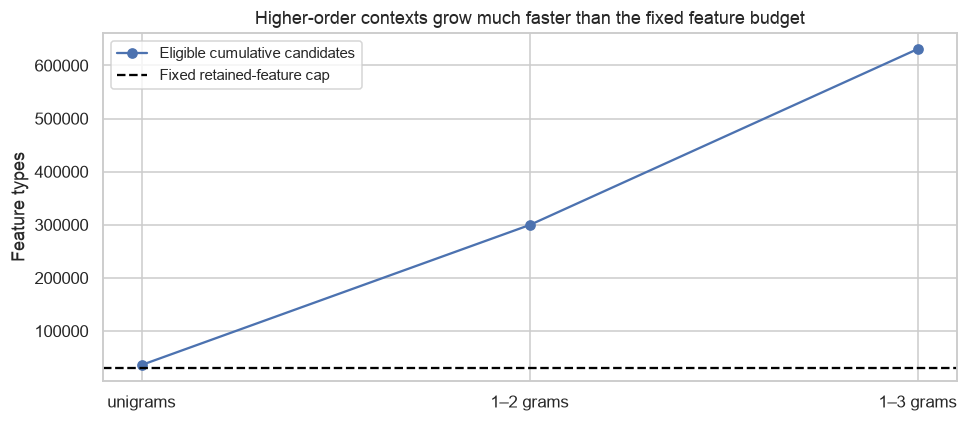

In [4]:
vocabulary_growth=[]
for order in [1,2,3]:
    document_frequency=Counter()
    for tokens in base_tokens:
        document_frequency.update(set(" ".join(tokens[i:i+order]) for i in range(len(tokens)-order+1)))
    vocabulary_growth.append({"order":order,"observed_types":len(document_frequency),
                              "eligible_min_df_2":sum(count>=MIN_DF for count in document_frequency.values())})
    del document_frequency
vocabulary_growth=pd.DataFrame(vocabulary_growth)
vocabulary_growth["cumulative_eligible"]=vocabulary_growth.eligible_min_df_2.cumsum()
representations={};feature_records=[];representation_times={}
for method,(tfidf,max_n) in SPARSE_CONFIGS.items():
    started=perf_counter()
    vectorizer=word_vectorizer(tfidf=tfidf,max_n=max_n,max_features=MAX_FEATURES,min_df=MIN_DF)
    matrix=vectorizer.fit_transform(input_text).tocsr()
    names=vectorizer.get_feature_names_out()
    representations[method]=matrix
    eligible=int(vocabulary_growth.loc[vocabulary_growth.order.le(max_n),"eligible_min_df_2"].sum())
    feature_records.append({"method":method,"features":len(names),"eligible_candidates":eligible,
        "eligible_retained_pct":100*len(names)/eligible,"cap_reached":len(names)==MAX_FEATURES,
        "unigram_features":sum(" " not in name for name in names),
        "bigram_features":sum(name.count(" ")==1 for name in names),
        "trigram_features":sum(name.count(" ")==2 for name in names),
        "distinct_component_words":len(set(word for name in names for word in name.split()))})
    representation_times[method]=perf_counter()-started
    del vectorizer
feature_table=pd.DataFrame(feature_records).set_index("method")
show_table(vocabulary_growth,"Uncapped TRAIN candidate growth (before frequency cap)",index=False)
show_table(feature_table[["features","eligible_candidates","eligible_retained_pct","cap_reached"]].round(3),
           "Measured fixed-cap effect")
show_table(feature_table[["unigram_features","bigram_features","trigram_features","distinct_component_words"]],
           "Actual n-gram orders in retained features")
assert feature_table.loc['TF-IDF 1-2','bigram_features']>0 and feature_table.loc['TF-IDF 1-3','trigram_features']>0
fig,ax=plt.subplots(figsize=(9,4))
ax.plot([1,2,3],vocabulary_growth.cumulative_eligible,marker="o",label="Eligible cumulative candidates")
ax.axhline(MAX_FEATURES,color="black",linestyle="--",label="Fixed retained-feature cap")
ax.set_xticks([1,2,3],["unigrams","1–2 grams","1–3 grams"])
ax.set(ylabel="Feature types",title="Higher-order contexts grow much faster than the fixed feature budget")
ax.legend(fontsize=10);plt.tight_layout();plt.show()
display(prose(f"**Measured:** eligible cumulative candidates grow from "
              f"**{int(vocabulary_growth.iloc[0].cumulative_eligible):,}** to "
              f"**{int(vocabulary_growth.iloc[-1].cumulative_eligible):,}**; retained features are capped at "
              f"**{MAX_FEATURES:,}**. Thus a constant matrix width does not mean higher-order vocabularies "
              "stopped growing; frequent n-grams compete with unigrams for the same budget."))

### 2 — TRAIN-fitted Word2Vec and document mean pooling

CBOW predicts a center word from the mean of nearby context embeddings; Skip-gram predicts
nearby words from a center embedding. We select **CBOW**, a fixed efficient CPU baseline,
not a claim that it dominates Skip-gram. With negative sampling, a positive context/word
score is increased and sampled negative scores decreased, schematically:

$$
\log\sigma(u_w^T\bar v_C)+\sum_{k=1}^{5}\mathbb E_{n\sim P_n}
\log\sigma(-u_n^T\bar v_C).
$$

Use vector_size=100, window=5, min_count=2, negative=5, sample=1e-3, 10 epochs, workers=1,
seed=42 and a stable CRC32 initialization hash. Context windows stay within product token
lists; labels and assessment text are not supplied. The word vocabulary/weights are learned
from all TRAIN for descriptive analysis only.

Pool every occurrence of an in-vocabulary token equally:

$$z_d=\frac1{|K_d|}\sum_{w\in K_d}v_w.$$

Repeated words receive repeated weight. Discard OOV tokens from the mean and report them;
if $K_d$ is empty return a zero vector while keeping the record. Pooling loses order and
contextual senses, and common words can dominate. No full-TRAIN Word2Vec vectors are reused
for inductive CV; this chapter deliberately reports no Word2Vec classifier CV score.

**Essential compatibility exception.** The PyPI 4.4.0 Cython BLAS wrapper can turn a legitimate
−1 dot product into 0 ([upstream issue #3665](https://github.com/piskvorky/gensim/issues/3665)).
Use the exact reviewed source commit `ecf22c266f3b8930610114c149d8991ed14e2a16` from
[the open fix PR #3668](https://github.com/piskvorky/gensim/pull/3668), not a floating branch.
The fix marks two native dot-function pointers `noexcept`; it does not change the Word2Vec
objective. This is an unmerged third-party source pin and requires a C compiler when building.
The public hierarchical-softmax sign-symmetry regression runs before training, covering CBOW/
Skip-gram and two widths; failure stops execution. Weight updates, finite loss/vectors and
full raw-word training counts are also checked. Reported results use the corrected build;
exploratory outputs from the defective wheel are discarded. All earlier project pins stay fixed.

`min_count` counts token occurrences, while sparse `min_df` counts documents; their learned
vocabulary sizes therefore have different frequency denominators even before the feature cap.

In [5]:
started=perf_counter()
# Explicit build/train also verifies updates rather than accepting initialized embeddings.
w2v_numeric_check=word2vec_numeric_guard()
gensim_source=json.loads(distribution('gensim').read_text('direct_url.json'))
assert gensim_source['vcs_info']['commit_id']=='ecf22c266f3b8930610114c149d8991ed14e2a16'
with threadpool_limits(limits=2):
    w2v_model=Word2Vec(**W2V_PARAMETERS)
    w2v_model.build_vocab(base_tokens.tolist())
    initialized_vectors=w2v_model.wv.vectors.copy()
    trained_effective_words,trained_raw_words=w2v_model.train(base_tokens.tolist(),
        total_examples=len(base_tokens),epochs=W2V_PARAMETERS['epochs'],compute_loss=True)
    training_update_norm=float(np.linalg.norm(w2v_model.wv.vectors-initialized_vectors))
    del initialized_vectors
    assert np.isfinite(w2v_model.wv.vectors).all() and training_update_norm>0
    assert np.isfinite(w2v_model.get_latest_training_loss())
    w2v_vectors,w2v_coverage=mean_word_vectors(base_tokens.tolist(),w2v_model.wv)
assert trained_raw_words==sum(map(len,base_tokens))*W2V_PARAMETERS['epochs']
assert np.isfinite(w2v_vectors).all()
representation_times["Word2Vec"]=perf_counter()-started
representations["Word2Vec"]=w2v_vectors
w2v_vocabulary=len(w2v_model.wv)
w2v_report=pd.Series({"algorithm":"CBOW, negative sampling","documents_fit":len(train),
    "learned_word_vocabulary":w2v_vocabulary,"vector_size":w2v_model.vector_size,
    "window":5,"min_count":2,"negative":5,"epochs":10,"workers":1,"seed":42,
    "stable_hash":"CRC32","weight_update_L2":training_update_norm,
    "effective_training_words":trained_effective_words,"raw_training_words":trained_raw_words,
    "finite_training_loss":bool(np.isfinite(w2v_model.get_latest_training_loss())),
    "BLAS_regression_cases_passed":w2v_numeric_check['passed_cases'],
    "BLAS_regression_max_error":w2v_numeric_check['max_symmetry_error'],
    "gensim_source_commit":gensim_source['vcs_info']['commit_id'],"seconds_fit_and_pool":representation_times["Word2Vec"],**w2v_coverage},name="observed")
show_table(w2v_report.to_frame(),"Word2Vec training and pooling provenance")
display(prose(f"**Measured:** Word2Vec learns **{w2v_vocabulary:,}** word types and produces "
              f"**{w2v_vectors.shape[1]}**-dimensional document means. TRAIN occurrence OOV = "
              f"**{w2v_coverage['OOV_rate']:.3%}**, zero documents = **{w2v_coverage['zero_documents']}**. "
              "This coverage is relative to its TRAIN min_count policy, not test-vocabulary coverage."))

,observed
algorithm,"CBOW, negative sampling"
documents_fit,22201
learned_word_vocabulary,40880
vector_size,100
window,5
min_count,2
negative,5
epochs,10
workers,1
seed,42


### 3 — Frozen pretrained MiniLM, real model revision and truncation audit

Load the actual public `sentence-transformers/all-MiniLM-L6-v2` at the pinned commit shown
below, with no fine-tuning or labels. The [model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2)
describes a 384-dimensional mean-pooled sentence encoder. Public pretrained knowledge is
external information, not learned from this project's assessment partition; pretraining overlap
with public product text cannot be ruled out.

Use CPU, float32, four torch threads, batch size 32, eval mode, all parameters frozen and
L2-normalized output. Verify actual output size, tokenizer vocabulary, model length limit,
revision and local safetensors hash. Audit **actual subword lengths including special tokens**
before truncation; whitespace-word counts cannot determine encoder truncation. Keep the model's
configured limit rather than tuning it. Empty common strings, if any, are assigned zero
vectors consistently with missing-content rows in other representations; no row is removed.
This is one fixed generic pretrained encoder, not a universal semantic or domain-performance guarantee.

In [6]:
started=perf_counter()
try:
    snapshot=snapshot_download(MODEL_NAME,revision=MODEL_REVISION,cache_dir=str(MODEL_CACHE),
                               allow_patterns=MODEL_FILES,token=False,local_files_only=True)
    model_preparation="exact local model revision reused"
except Exception:
    try:
        snapshot=snapshot_download(MODEL_NAME,revision=MODEL_REVISION,cache_dir=str(MODEL_CACHE),
                                   allow_patterns=MODEL_FILES,token=False)
        model_preparation="downloaded public model revision once"
    except Exception:
        raise RuntimeError("Cannot obtain sentence-transformers/all-MiniLM-L6-v2 at revision "+MODEL_REVISION+
            ". Check network access to huggingface.co and install the pinned lock, then rerun. "
            "Weights are stored under .cache/huggingface; no substitute embeddings are generated.") from None
encoder=SentenceTransformer(snapshot,device="cpu",local_files_only=True,trust_remote_code=False)
encoder.eval();encoder.requires_grad_(False)
assert not any(parameter.requires_grad for parameter in encoder.parameters())
assert encoder.get_embedding_dimension()==384
max_sequence_length=int(encoder.max_seq_length)
model_load_seconds=perf_counter()-started
subword_lengths=[]
for offset in range(0,len(input_text),256):
    batch=input_text.iloc[offset:offset+256].tolist()
    lengths=encoder.tokenizer(batch,add_special_tokens=True,truncation=False,return_length=True,verbose=False)["length"]
    subword_lengths.extend(lengths)
subword_lengths=np.asarray(subword_lengths)
truncation_report=pd.Series({"model_max_seq_length":max_sequence_length,
    "TRAIN_subword_mean":subword_lengths.mean(),"TRAIN_subword_median":np.median(subword_lengths),
    "TRAIN_subword_P95":np.quantile(subword_lengths,.95),"TRAIN_subword_max":subword_lengths.max(),
    "documents_over_model_limit":int((subword_lengths>max_sequence_length).sum()),
    "pct_over_model_limit":100*(subword_lengths>max_sequence_length).mean()},name="measured")
started=perf_counter()
minilm_vectors=frozen_sentence_vectors(encoder,input_text.tolist(),batch_size=32)
representation_times["MiniLM"]=perf_counter()-started
assert minilm_vectors.shape==(len(train),384) and np.isfinite(minilm_vectors).all()
representations["MiniLM"]=minilm_vectors
model_provenance=pd.Series({"name":MODEL_NAME,"revision":MODEL_REVISION,"output_dimensions":minilm_vectors.shape[1],
    "pretrained_subword_vocab":encoder.tokenizer.vocab_size,"device":str(encoder.device),"dtype":str(minilm_vectors.dtype),
    "batch_size":32,"normalize_embeddings":True,"fine_tuned":False,
    "load_seconds":model_load_seconds,"encode_seconds":representation_times["MiniLM"],
    "weights_SHA256":hashlib.sha256((Path(snapshot)/"model.safetensors").read_bytes()).hexdigest()},name="observed")
print(model_preparation)
show_table(model_provenance.to_frame(),"Real model configuration/provenance",collapse=True)
show_table(truncation_report.to_frame().round(3),"Measured encoder truncation exposure")
display(prose(f"**Measured:** real pretrained output shape **{minilm_vectors.shape}**, CPU encoding "
              f"**{representation_times['MiniLM']:.1f} seconds**. **{int(truncation_report.documents_over_model_limit):,}** "
              f"TRAIN texts (**{truncation_report.pct_over_model_limit:.2f}%**) exceed the actual "
              f"**{max_sequence_length}**-subword limit. Long descriptions therefore lose suffix information "
              "in this fixed encoder, unlike full-length sparse/count pooling representations; that is a material comparison limit."))

exact local model revision reused


,observed
name,sentence-transformers/all-MiniLM-L6-v2
revision,1110a243fdf4706b3f48f1d95db1a4f5529b4d41
output_dimensions,384
pretrained_subword_vocab,30522
device,cpu
dtype,float32
batch_size,32
normalize_embeddings,True
fine_tuned,False
load_seconds,0.206867


,measured
model_max_seq_length,256.000
TRAIN_subword_mean,134.287
TRAIN_subword_median,93.000
TRAIN_subword_P95,358.000
TRAIN_subword_max,9137.000
documents_over_model_limit,2864.000
pct_over_model_limit,12.900


### 4 — Dimensions, numerical sparsity, storage and zero vectors

$$\mathrm{sparsity}=1-\frac{nnz}{N D}.$$

For sparse matrices count actual numerical nonzeros, not allocated zero entries. CSR storage
is the sum of data/indices/indptr buffers; dense storage is array `nbytes`, excluding Python
objects/model weights. The hypothetical dense equivalent is arithmetic only, never allocated.
Dense embeddings are not sparse feature models merely because some coordinates equal zero;
an all-OOV Word2Vec document is different from an ordinary dense vector with a zero coordinate.
No usable vocabulary/empty documents stay as zero rows. Learned word counts apply to BoW/
Word2Vec; MiniLM's subword vocabulary was learned externally, not on TRAIN.

In [7]:
profile_rows=[]
for method,matrix in representations.items():
    report=matrix_profile(matrix)
    if method in SPARSE_CONFIGS:
        words=int(feature_table.loc[method,"distinct_component_words"])
        source="TRAIN fitted features"
    elif method=="Word2Vec": words=w2v_vocabulary;source="TRAIN learned words"
    else: words=None;source="external pretrained subwords"
    profile_rows.append({"method":method,**report,"learned_component_words":words,"vocab_source":source,
                         "shape":str(matrix.shape),"construction_seconds":representation_times[method]})
representation_table=pd.DataFrame(profile_rows).set_index("method")
show_table(representation_table[["documents","dimensions","nnz","sparsity","zero_documents"]].round(6),
           "All TRAIN document-vector shapes and numerical sparsity")
show_table(pd.DataFrame({"Layout":representation_table.layout,
    "Stored MiB":representation_table.storage_bytes/1024**2,
    "Dense equivalent MiB":representation_table.dense_equivalent_bytes/1024**2,
    "Build / encode seconds":representation_table.construction_seconds}).round(3),"Measured vector storage and runtime")
show_table(representation_table[["shape","learned_component_words","vocab_source"]],"Vocabulary meaning by representation",collapse=True)
assert all(matrix.shape[0]==len(train) for matrix in representations.values())

,documents,dimensions,nnz,sparsity,zero_documents
method,,,,,
BoW,22201,30000,1550939,0.997671,4
TF-IDF 1,22201,30000,1550939,0.997671,4
TF-IDF 1-2,22201,30000,2341310,0.996485,20
TF-IDF 1-3,22201,30000,2476466,0.996282,26
Word2Vec,22201,100,2220000,0.000045,1
MiniLM,22201,384,8525184,0.000000,0


,Layout,Stored MiB,Dense equivalent MiB,Build / encode seconds
method,,,,
BoW,CSR,17.834,5081.406,0.745
TF-IDF 1,CSR,17.834,5081.406,0.735
TF-IDF 1-2,CSR,26.879,5081.406,3.740
TF-IDF 1-3,CSR,28.426,5081.406,9.697
Word2Vec,dense,8.469,8.469,32.930
MiniLM,dense,32.521,32.521,210.465


,shape,learned_component_words,vocab_source
method,,,
BoW,"(22201, 30000)",30000.0,TRAIN fitted features
TF-IDF 1,"(22201, 30000)",30000.0,TRAIN fitted features
TF-IDF 1-2,"(22201, 30000)",10811.0,TRAIN fitted features
TF-IDF 1-3,"(22201, 30000)",9661.0,TRAIN fitted features
Word2Vec,"(22201, 100)",40880.0,TRAIN learned words
MiniLM,"(22201, 384)",NaN,external pretrained subwords


### 5 — Same/different-category cosine on identical sampled pairs

$$\cos(x_i,x_j)=\frac{x_i^T x_j}{\|x_i\|_2\|x_j\|_2}.$$

Use row-wise sparse multiplication or dense paired dot products after L2 normalization,
not a full TRAIN×TRAIN matrix. The quotas give each category equal weight for same-class
pairs and each category pair equal weight for different-class pairs. Sampling uses true labels
only to define this descriptive comparison; labels never enter encoder training. Report mean,
median and IQR plus mean gaps, without an unsupported significance test. Cosine magnitudes
across different representations need not share the same baseline or semantic interpretation.

,mean_different,mean_same,median_different,median_same,mean_same_minus_different
method,,,,,
BoW,0.15051,0.18366,0.12237,0.15090,0.03315
TF-IDF 1,0.02075,0.03547,0.01609,0.02850,0.01472
TF-IDF 1-2,0.01497,0.02707,0.01100,0.02071,0.01210
TF-IDF 1-3,0.01455,0.02666,0.01071,0.01980,0.01212
Word2Vec,0.34383,0.55791,0.35229,0.59367,0.21408
MiniLM,0.08312,0.19660,0.07457,0.18686,0.11348


method,pair_type,pairs,mean,median,Q1,Q3,SD,zero_vector_pairs
BoW,same,2400,0.183664,0.150904,0.051427,0.275221,0.160903,2
BoW,different,2400,0.150513,0.122375,0.032209,0.240825,0.136726,2
TF-IDF 1,same,2400,0.035469,0.028503,0.008137,0.051915,0.035292,2
TF-IDF 1,different,2400,0.020746,0.016093,0.003963,0.032378,0.020092,2
TF-IDF 1-2,same,2400,0.027068,0.020713,0.005891,0.038854,0.030556,5
TF-IDF 1-2,different,2400,0.014967,0.011002,0.002904,0.022796,0.015177,8
TF-IDF 1-3,same,2400,0.026665,0.019800,0.005838,0.037820,0.031169,8
TF-IDF 1-3,different,2400,0.014548,0.010714,0.002857,0.021767,0.015053,8
Word2Vec,same,2400,0.557911,0.593669,0.425529,0.725692,0.218960,1
Word2Vec,different,2400,0.343832,0.352294,0.153895,0.541930,0.250220,1


Pair-ID SHA-256: bc1f399d8ef08c6706f756bc9be9a2e0cb974d50b6b3132788e6bf5528341026


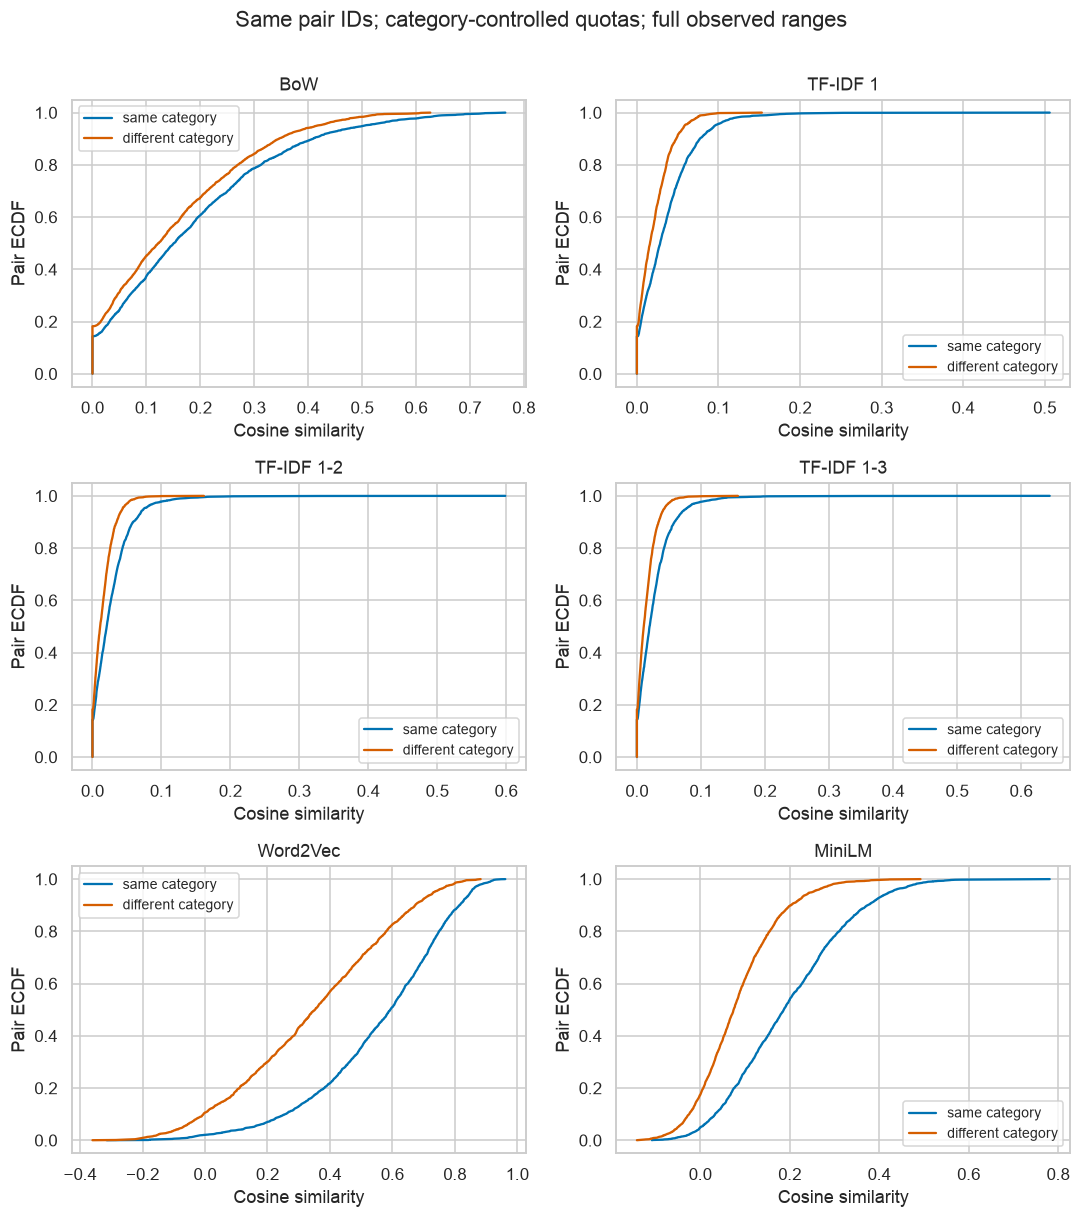

In [8]:
pair_table=sample_document_pairs(y,same_per_class=600,different_per_class_pair=400,seed=PAIR_SEED)
pair_indices=pair_table[["i","j"]].to_numpy()
assert not np.any(pair_indices[:,0]==pair_indices[:,1])
assert not pair_table[["i","j"]].duplicated().any()
pair_ID_hash=hashlib.sha256(train.row_id.to_numpy()[pair_indices].astype("<i8").tobytes()).hexdigest()
show_table(pair_table.groupby(["same_class","class_a","class_b"]).size().rename("pairs").to_frame(),
           "Fixed class-controlled pair quotas",collapse=True)
cosine_records=[];similarity_values={}
for method,matrix in representations.items():
    values=paired_cosines(matrix,pair_indices)
    similarity_values[method]=values
    norms=row_norms(matrix)
    for same in [True,False]:
        mask=pair_table.same_class.to_numpy()==same
        selected=values[mask]
        zero_pairs=np.any(norms[pair_indices[mask]]==0,axis=1).sum()
        cosine_records.append({"method":method,"pair_type":"same" if same else "different","pairs":len(selected),
            "mean":selected.mean(),"median":np.median(selected),"Q1":np.quantile(selected,.25),
            "Q3":np.quantile(selected,.75),"SD":selected.std(ddof=1),"zero_vector_pairs":int(zero_pairs)})
cosine_table=pd.DataFrame(cosine_records)
cosine_summary=cosine_table.pivot(index="method",columns="pair_type",values=["mean","median"]).reindex(representations)
cosine_summary.columns=[f"{metric}_{kind}" for metric,kind in cosine_summary.columns]
cosine_summary["mean_same_minus_different"]=cosine_summary.mean_same-cosine_summary.mean_different
show_table(cosine_summary.round(5),"Cosine summaries on exactly the same TRAIN pair IDs")
show_table(cosine_table.round(6),"All pair counts, quartiles, SD and zero-pair counts",collapse=True,index=False)
print("Pair-ID SHA-256:",pair_ID_hash)
fig,axes=plt.subplots(3,2,figsize=(10,11))
for ax,(method,values) in zip(axes.flat,similarity_values.items()):
    for same,label,color in [(True,"same category","#0072B2"),(False,"different category","#D55E00")]:
        selected=values[pair_table.same_class.to_numpy()==same]
        selected=np.sort(selected)
        ax.plot(selected,np.arange(1,len(selected)+1)/len(selected),label=label,color=color)
    ax.set(title=method,xlabel="Cosine similarity",ylabel="Pair ECDF")
    ax.legend(fontsize=9)
fig.suptitle("Same pair IDs; category-controlled quotas; full observed ranges",y=1.005)
plt.tight_layout();plt.show()
largest_gap=cosine_summary.mean_same_minus_different.idxmax()
display(prose(f"**Measured:** largest same-minus-different mean gap is **{largest_gap}** "
              f"(**{cosine_summary.loc[largest_gap,'mean_same_minus_different']:.4f}**). "
              "This is a descriptive contrast under balanced quotas, not a proof of superior classification. "
              "Product templates and remaining variants can raise similarity, and a uniformly high cosine baseline can hide weak class contrast."))

### 6 — Original-space silhouette and K-Means, with distinct label meanings

For point $i$, $a_i$ is its mean within-group distance and $b_i$ the smallest mean distance to
another group:

$$s_i=\frac{b_i-a_i}{\max(a_i,b_i)},\qquad S=\frac1N\sum_i s_i.$$

**True-label** groups describe category separation. **K-Means-label** groups describe the
clusters found by an unsupervised algorithm, not category correctness. Both main scores use
cosine in the original unit-vector representation; Euclidean scores provide a fixed metric
sensitivity. A high cluster silhouette can coexist with poor category agreement. K=4 matches
category count without guaranteeing that the partitions match.

Use a single balanced 1,200-row candidate subset and common nonzero intersection across all
representations; report any exclusions and final supports. The bounded silhouette computation
may internally use O(n²) distances for this subset, never the full 22,201-row population.
Invalid label counts/zero vectors produce explicit status + NaN, not an invented score.
All clustering uses identical IDs/configuration. Highlight TF-IDF unigram versus MiniLM as
the predeclared advanced comparison; other representations provide the same descriptive context.

In [9]:
candidate_subset=balanced_subset(y,per_class=PER_CLASS,seed=SUBSET_SEED)
common_nonzero=np.ones(len(candidate_subset),dtype=bool)
for matrix in representations.values(): common_nonzero &= row_norms(matrix[candidate_subset])>0
geometry_indices=candidate_subset[common_nonzero]
geometry_labels=y[geometry_indices]
geometry_ID_hash=hashlib.sha256(train.iloc[geometry_indices].row_id.to_numpy(dtype="<i8").tobytes()).hexdigest()
geometry_support=pd.Series(geometry_labels).value_counts().reindex(LABELS).rename("geometry_N").to_frame()
show_table(geometry_support,"Same common nonzero TRAIN subset for all six representations")
print("Candidate subset N:",len(candidate_subset),"| common nonzero N:",len(geometry_indices),
      "| exclusions from every geometry:",int((~common_nonzero).sum()))
print("Geometry-ID SHA-256:",geometry_ID_hash)
geometry_matrices={method:normalize(matrix[geometry_indices],norm="l2",copy=True)
                   for method,matrix in representations.items()}
geometry_rows=[];cluster_rows=[];cluster_assignments={};geometry_warning_records=[]
with threadpool_limits(limits=2):
    for method,matrix in geometry_matrices.items():
        started=perf_counter()
        clustering=KMeans(n_clusters=4,init="k-means++",n_init=10,max_iter=300,
                          random_state=42,algorithm="lloyd")
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            labels=clustering.fit_predict(matrix)
        for warning in caught:
            geometry_warning_records.append({"method":method,"category":warning.category.__name__,"message":str(warning.message)})
            warnings.warn(str(warning.message),warning.category)
        cluster_assignments[method]=labels
        row={"method":method,"N":len(labels),"ARI":adjusted_rand_score(geometry_labels,labels)}
        for metric in ["cosine","euclidean"]:
            for label_name,group_labels in [("true",geometry_labels),("cluster",labels)]:
                value,status=safe_silhouette(matrix,group_labels,metric=metric)
                row[f"{label_name}_{metric}"]=value
                row[f"{label_name}_{metric}_status"]=status
        row["seconds"]=perf_counter()-started
        geometry_rows.append(row)
        cluster_rows.append({"method":method,**{f"cluster_{k}":int((labels==k).sum()) for k in range(4)}})
geometry_table=pd.DataFrame(geometry_rows).set_index("method")
cluster_sizes=pd.DataFrame(cluster_rows).set_index("method")
show_table(geometry_table[["true_cosine","cluster_cosine","ARI"]].round(5),
           "Original-space category separation versus discovered-cluster separation")
show_table(cluster_sizes,"K=4 cluster sizes; IDs have no category meaning")
show_table(geometry_table[["true_euclidean","cluster_euclidean","seconds"]].round(5),
           "Declared Euclidean-distance sensitivity")
show_table(geometry_table.filter(like="status"),"Silhouette validity statuses",collapse=True)
show_table(pd.DataFrame(geometry_warning_records,columns=["method","category","message"]),"Actual clustering warnings",collapse=True,index=False)
advanced_geometry=geometry_table.loc[["TF-IDF 1","MiniLM"],["true_cosine","cluster_cosine","ARI"]]
show_table(advanced_geometry.round(6),"Predeclared TF-IDF versus Sentence Transformer K-Means comparison")
display(prose(f"**Measured:** TF-IDF true/cluster cosine silhouettes = "
              f"**{geometry_table.loc['TF-IDF 1','true_cosine']:.4f} / {geometry_table.loc['TF-IDF 1','cluster_cosine']:.4f}**; "
              f"MiniLM = **{geometry_table.loc['MiniLM','true_cosine']:.4f} / {geometry_table.loc['MiniLM','cluster_cosine']:.4f}**. "
              "Cluster cohesion and category separation are different measurements; inspect cluster sizes "
              "and ARI before interpreting the clusters as product categories."))

,geometry_N
Household,300
Books,300
Clothing & Accessories,300
Electronics,300


Candidate subset N: 1200 | common nonzero N: 1200 | exclusions from every geometry: 0
Geometry-ID SHA-256: 2c624ece21bf96955527d1742bcf996f548a6969360be4d5e4a57aab88ca9fa2


,true_cosine,cluster_cosine,ARI
method,,,
BoW,0.01260,0.00815,0.09914
TF-IDF 1,0.01125,0.01190,0.32645
TF-IDF 1-2,0.00940,0.00949,0.24517
TF-IDF 1-3,0.00936,0.01101,0.15500
Word2Vec,0.18698,0.26925,0.41133
MiniLM,0.08572,0.10477,0.72719


,cluster_0,cluster_1,cluster_2,cluster_3
method,,,,
BoW,264,377,321,238
TF-IDF 1,337,441,245,177
TF-IDF 1-2,302,159,547,192
TF-IDF 1-3,9,153,169,869
Word2Vec,245,277,254,424
MiniLM,291,319,314,276


,true_euclidean,cluster_euclidean,seconds
method,,,
BoW,0.00737,0.00545,0.26936
TF-IDF 1,0.00583,0.00616,0.19702
TF-IDF 1-2,0.00488,0.00490,0.22977
TF-IDF 1-3,0.00487,0.00632,0.25562
Word2Vec,0.11004,0.15653,0.11058
MiniLM,0.04590,0.05602,0.16471


,true_cosine_status,cluster_cosine_status,true_euclidean_status,cluster_euclidean_status
method,,,,
BoW,ok,ok,ok,ok
TF-IDF 1,ok,ok,ok,ok
TF-IDF 1-2,ok,ok,ok,ok
TF-IDF 1-3,ok,ok,ok,ok
Word2Vec,ok,ok,ok,ok
MiniLM,ok,ok,ok,ok


method,category,message


,true_cosine,cluster_cosine,ARI
method,,,
TF-IDF 1,0.011249,0.011900,0.326454
MiniLM,0.085719,0.104771,0.727192


### 7 — Same-subset SVD → t-SNE, separate from silhouette

Fit one 50-component randomized TruncatedSVD per representation **on the common TRAIN
geometry subset**, not the assessment or full classifier folds. Report retained variance,
then L2-normalize reduced rows and fit the same t-SNE settings. Dense and sparse families use
the same reduction convention; SVD is uncentered, so retained-variance ratios are descriptive.
Each panel has its own nonlinear coordinates, with arbitrary scale/orientation; clusters can
look isolated even when original-space category silhouettes are small. No scores below are
computed from t-SNE, and a pretty layout is not a classifier result. We do not search
perplexities/seeds for a more favorable picture.

,N,SVD_components,SVD_explained_variance_sum,perplexity,tSNE_iterations,KL_divergence,seconds
method,,,,,,,
BoW,1200,50,0.35773,30,999,1.57951,3.63957
TF-IDF 1,1200,50,0.14281,30,999,1.08816,4.30962
TF-IDF 1-2,1200,50,0.12774,30,999,1.09418,3.96232
TF-IDF 1-3,1200,50,0.12851,30,999,1.09716,4.07266
Word2Vec,1200,50,0.94879,30,999,1.06713,3.42550
MiniLM,1200,50,0.57582,30,999,1.11330,3.05453


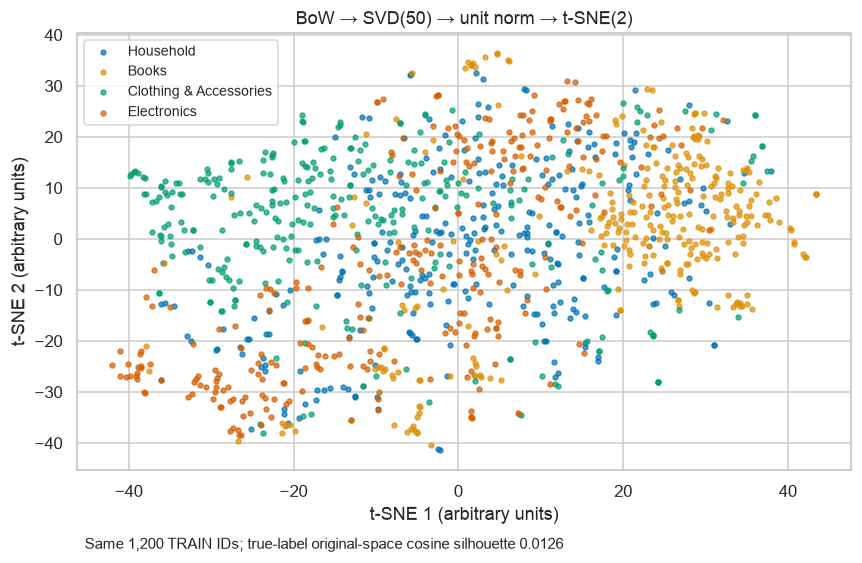

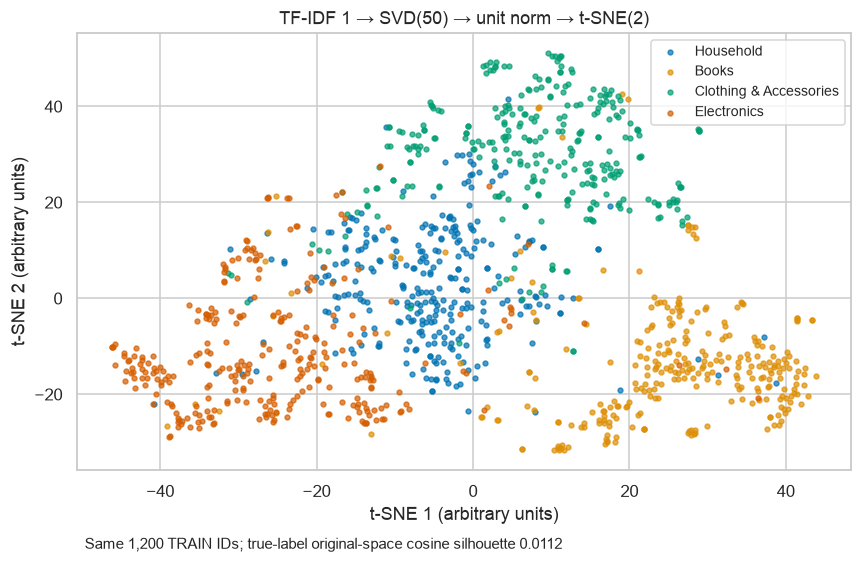

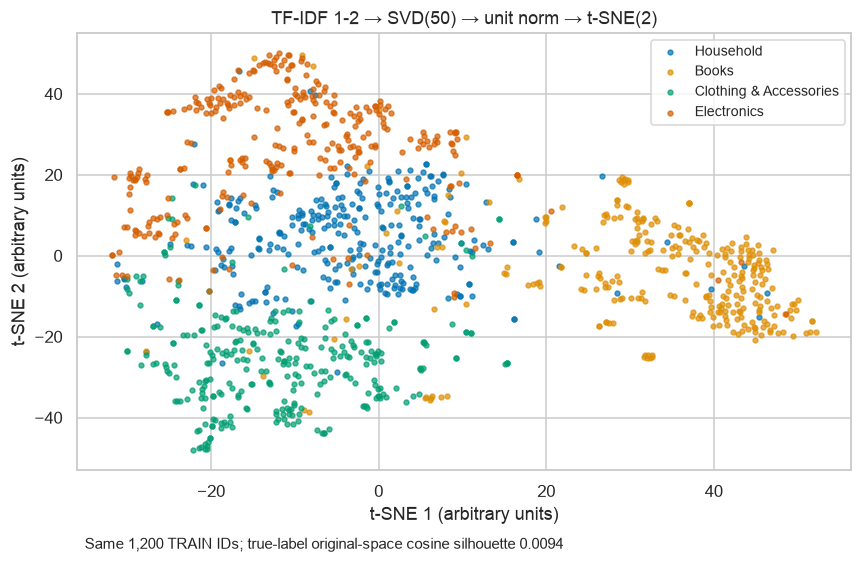

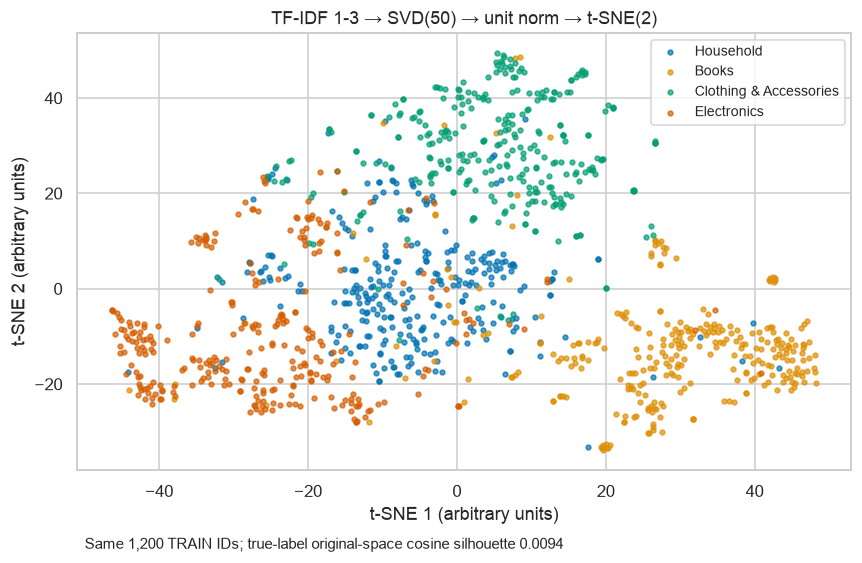

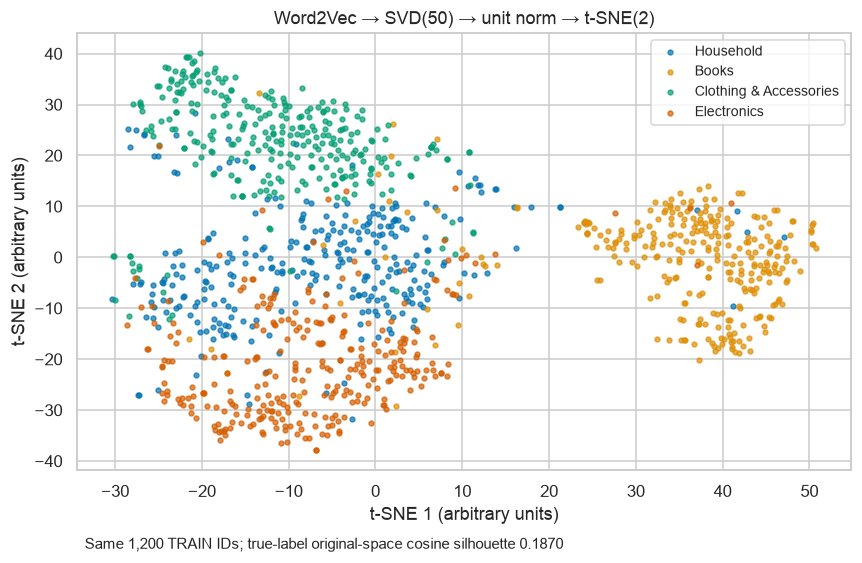

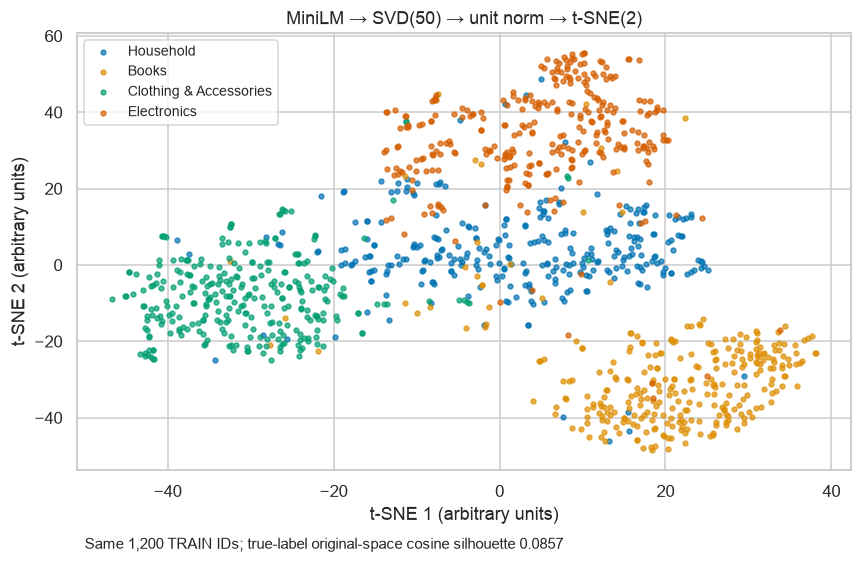

In [10]:
tsne_coordinates={};reduction_rows=[]
with threadpool_limits(limits=2):
    for method,matrix in geometry_matrices.items():
        started=perf_counter()
        svd=TruncatedSVD(n_components=50,n_iter=7,random_state=42)
        reduced=normalize(svd.fit_transform(matrix),norm="l2")
        projection=TSNE(n_components=2,perplexity=30,learning_rate="auto",init="pca",metric="euclidean",
                         max_iter=1000,random_state=42,method="barnes_hut",n_jobs=2)
        coords=projection.fit_transform(reduced)
        tsne_coordinates[method]=coords
        reduction_rows.append({"method":method,"N":len(coords),"SVD_components":50,
            "SVD_explained_variance_sum":svd.explained_variance_ratio_.sum(),
            "perplexity":30,"tSNE_iterations":projection.n_iter_,"KL_divergence":projection.kl_divergence_,
            "seconds":perf_counter()-started})
reduction_table=pd.DataFrame(reduction_rows).set_index("method")
show_table(reduction_table.round(5),"Recorded reduction parameters and diagnostics",collapse=True)
# One large readable figure per representation; consistent color/category legend.
colors=dict(zip(LABELS,sns.color_palette("colorblind",4)))
for method,coords in tsne_coordinates.items():
    fig,ax=plt.subplots(figsize=(8,5.3))
    for label in LABELS:
        mask=geometry_labels==label
        ax.scatter(coords[mask,0],coords[mask,1],s=10,alpha=.7,label=label,color=colors[label])
    ax.set(title=f"{method} → SVD(50) → unit norm → t-SNE(2)",xlabel="t-SNE 1 (arbitrary units)",ylabel="t-SNE 2 (arbitrary units)")
    ax.legend(fontsize=9,loc="best")
    ax.text(.01,-.18,f"Same {len(geometry_indices):,} TRAIN IDs; true-label original-space cosine silhouette "
            f"{geometry_table.loc[method,'true_cosine']:.4f}",transform=ax.transAxes,fontsize=10)
    plt.tight_layout();plt.show()

### 8 — Controlled Linear SVM on the exact Stage 03 folds

The **encoder** defines a document's feature coordinates; the **classifier** learns a
label boundary in those coordinates. Frozen pretrained semantics do not remove the need
for supervised validation. Compare BoW and all three TF-IDF ranges with frozen MiniLM using
identical primal LinearSVC settings, row L2 normalization, data and group folds.

For each sparse fold, create a new pipeline: vectorizer → row Normalizer → SVM. Only fitting
rows determine vocabulary/IDF; validation calls `predict` only. MiniLM embeddings are fixed,
label-free and corpus-unadapted, so indexing the precomputed TRAIN array is permissible.
Its SVM still fits only fitting labels. Full-TRAIN sparse matrices from descriptive sections
are **not used in CV**. Word2Vec remains descriptive, avoiding a falsely inductive score from
full-TRAIN word embeddings. No held-out assessment classifier is trained/evaluated here.

Record convergence warnings and re-emit them, rather than suppressing them. All five macro-F1
scores, sample SD, accuracy and paired fold differences are visible. Fixed-fold rankings are
internal descriptive evidence, not statistical significance or a universal representation winner.

LinearSVC uses one-vs-rest linear decisions for the four categories. Equal C and unit row
norms define a controlled baseline, not identically optimized regularization in all spaces.

,mean_F1,sample_SD,mean_accuracy,mean_dimensions
method,,,,
BoW,0.953151,0.002563,0.953696,30000.0
TF-IDF 1,0.957514,0.001594,0.958155,30000.0
TF-IDF 1-2,0.955232,0.002086,0.955632,30000.0
TF-IDF 1-3,0.954483,0.002101,0.954912,30000.0
MiniLM,0.937824,0.003783,0.937976,384.0


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5
method,,,,,
BoW,0.956693,0.951316,0.951976,0.954988,0.950785
TF-IDF 1,0.959642,0.956834,0.955410,0.957328,0.958357
TF-IDF 1-2,0.958702,0.953372,0.953862,0.955099,0.955128
TF-IDF 1-3,0.957716,0.952269,0.953255,0.953967,0.955208
MiniLM,0.942919,0.939043,0.933506,0.938965,0.934687


,mean_seconds,max_iterations,convergence_warnings
method,,,
BoW,1.324,13,0
TF-IDF 1,1.294,12,0
TF-IDF 1-2,4.368,12,0
TF-IDF 1-3,8.981,13,0
MiniLM,1.955,8,0


method,fold,macro_F1,accuracy,fitted_dimensions,seconds,iterations,convergence_warnings
BoW,1,0.956693,0.957217,30000,1.374414,12,0
BoW,2,0.951316,0.951351,30000,1.204404,12,0
BoW,3,0.951976,0.952928,30000,1.237949,13,0
BoW,4,0.954988,0.955405,30000,1.263233,12,0
BoW,5,0.950785,0.951577,30000,1.539038,12,0
TF-IDF 1,1,0.959642,0.960594,30000,1.219061,11,0
TF-IDF 1,2,0.956834,0.957207,30000,1.195256,11,0
TF-IDF 1,3,0.955410,0.956306,30000,1.477494,12,0
TF-IDF 1,4,0.957328,0.957432,30000,1.290361,12,0
TF-IDF 1,5,0.958357,0.959234,30000,1.288203,12,0


method,fold,category,message


method,BoW,MiniLM,TF-IDF 1-2,TF-IDF 1-3
fold,,,,
1,-0.002949,-0.016723,-0.000940,-0.001926
2,-0.005517,-0.017791,-0.003462,-0.004564
3,-0.003434,-0.021904,-0.001548,-0.002155
4,-0.002340,-0.018363,-0.002229,-0.003360
5,-0.007573,-0.023670,-0.003230,-0.003149


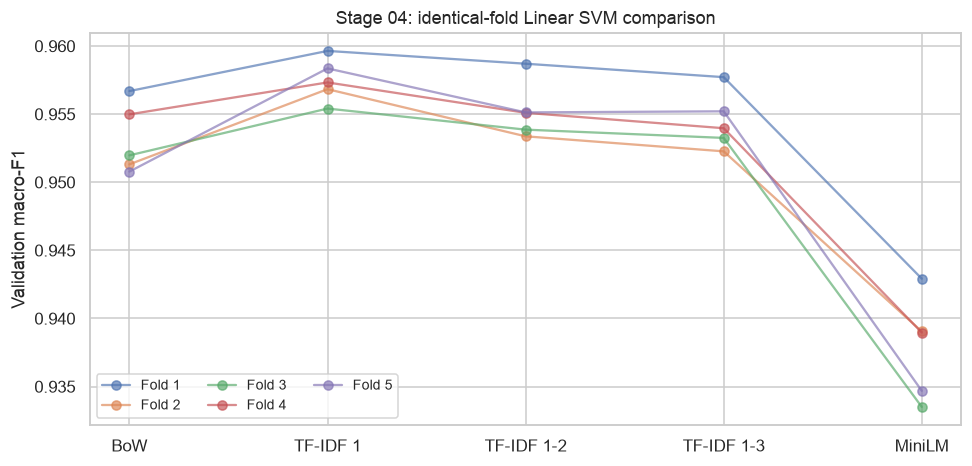

In [11]:
cv_records=[];cv_warning_records=[]
with threadpool_limits(limits=2):
    for method in [*SPARSE_CONFIGS,"MiniLM"]:
        for number,(fitting,validation) in enumerate(folds,1):
            started=perf_counter()
            if method=="MiniLM":
                estimator=linear_svm()
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter("always")
                    estimator.fit(minilm_vectors[fitting],y[fitting])
                    prediction=estimator.predict(minilm_vectors[validation])
                fitted_dimensions=minilm_vectors.shape[1]
            else:
                tfidf,max_n=SPARSE_CONFIGS[method]
                estimator=sparse_svm_pipeline(tfidf=tfidf,max_n=max_n,max_features=MAX_FEATURES,min_df=MIN_DF)
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter("always")
                    estimator.fit(input_text.iloc[fitting].tolist(),y[fitting])
                    prediction=estimator.predict(input_text.iloc[validation].tolist())
                fitted_dimensions=len(estimator.named_steps['vectorizer'].vocabulary_)
            for warning in caught:
                cv_warning_records.append({"method":method,"fold":number,"category":warning.category.__name__,"message":str(warning.message)})
                warnings.warn(str(warning.message),warning.category)
            classifier=estimator if method=="MiniLM" else estimator.named_steps['classifier']
            cv_records.append({"method":method,"fold":number,
                "macro_F1":f1_score(y[validation],prediction,average="macro",zero_division=0),
                "accuracy":accuracy_score(y[validation],prediction),"fitted_dimensions":fitted_dimensions,
                "seconds":perf_counter()-started,"iterations":int(np.max(classifier.n_iter_)),
                "convergence_warnings":sum(issubclass(w.category,ConvergenceWarning) for w in caught)})
            del estimator
cv_folds=pd.DataFrame(cv_records)
cv_summary=cv_folds.groupby('method',sort=False).agg(mean_F1=('macro_F1','mean'),sample_SD=('macro_F1','std'),
    mean_accuracy=('accuracy','mean'),mean_dimensions=('fitted_dimensions','mean'),
    mean_seconds=('seconds','mean'),max_iterations=('iterations','max'),convergence_warnings=('convergence_warnings','sum'))
cv_scores=cv_folds.pivot(index='method',columns='fold',values='macro_F1').reindex([*SPARSE_CONFIGS,'MiniLM'])
cv_scores.columns=[f'Fold {i}' for i in cv_scores.columns]
show_table(cv_summary[['mean_F1','sample_SD','mean_accuracy','mean_dimensions']].round(6),
           "New Stage 04 Linear SVM results: mean and sample SD")
show_table(cv_scores.round(6),"All five macro-F1 scores — identical Stage 03 fold memberships")
show_table(cv_summary[['mean_seconds','max_iterations','convergence_warnings']].round(3),"Actual runtime/convergence")
show_table(cv_folds.round(6),"All 25 fold records",collapse=True,index=False)
show_table(pd.DataFrame(cv_warning_records,columns=['method','fold','category','message']),"Actual CV warnings",collapse=True,index=False)
paired_scores=cv_folds.pivot(index='fold',columns='method',values='macro_F1')
paired_differences=paired_scores.subtract(paired_scores['TF-IDF 1'],axis=0).drop(columns='TF-IDF 1')
show_table(paired_differences.round(6),"Paired fold F1 differences versus TF-IDF unigram")
fig,ax=plt.subplots(figsize=(9,4.4))
for fold in range(1,6):
    values=cv_folds.loc[cv_folds.fold.eq(fold)].set_index('method').loc[list(cv_scores.index),'macro_F1']
    ax.plot(range(len(values)),values,marker='o',alpha=.65,label=f'Fold {fold}')
ax.set_xticks(range(len(cv_scores)),cv_scores.index)
ax.set(ylabel='Validation macro-F1',title='Stage 04: identical-fold Linear SVM comparison')
ax.legend(fontsize=9,ncol=3);plt.tight_layout();plt.show()
primary_delta=float(cv_summary.loc['MiniLM','mean_F1']-cv_summary.loc['TF-IDF 1','mean_F1'])
best_cv=cv_summary.mean_F1.idxmax()
display(prose(f"**Measured:** highest CV mean is **{best_cv}** (**{cv_summary.loc[best_cv,'mean_F1']:.5f}**). "
              f"MiniLM minus TF-IDF unigram mean macro-F1 = **{primary_delta:+.5f}**; paired fold range "
              f"**{paired_differences['MiniLM'].min():+.5f}** to **{paired_differences['MiniLM'].max():+.5f}**. "
              f"Total convergence warnings: **{int(cv_folds.convergence_warnings.sum())}**. "
              "The result belongs to this input policy, fixed C/cap, group recipe and corpus; semantic intuition alone cannot establish a winner."))

## Discussion

The result-driven synthesis below connects storage, local similarity, geometry and supervised
prediction without treating them as interchangeable objectives. Counts, vocabulary growth,
CPU time and model length constraints are practical parts of the comparison. The same
normalization deliberately keeps numbers but does not repair the earlier mention/brand risk
or lexical fragmentation of punctuation-separated model IDs.

Sparse feature selection by frequency/cap favors supported lexical patterns. Higher n-grams
can capture local context while competing for limited slots, creating a coverage/cost trade-off.
CBOW's in-domain word learning and document means supply a compact semantic baseline, but
order/sense averaging and common-word dominance can make unrelated products look similar.
The public MiniLM encoder brings contextual pretrained knowledge; generic-domain mismatch,
punctuation-reduced input and truncation of long descriptions can limit its advantage.

In this run the unigram TF-IDF SVM leads the fixed-C CV comparison, while MiniLM has
stronger category-aligned K-Means geometry. Word2Vec has the largest same/different cosine
gap and higher cluster silhouette, yet MiniLM's clusters agree more closely with categories
by ARI. Thus the rankings answer different questions. The n-gram cap allocates many slots to
frequent phrases, displacing unigram coverage; cumulative n-grams do not improve the observed
fixed-cap SVM means. These are observations of this protocol, not claims that phrases or
pretrained embeddings are intrinsically inferior. Only trained sparse features with enough
support survive; representation zero-row counts reveal the cost to a few short/code-heavy inputs.

Similarity compares selected pairs; true-label silhouette assesses a balanced subset's category
geometry; K-Means silhouette describes discovered clusters; an SVM learns supervised boundaries.
Different values/rankings across these tasks need not be contradictory. t-SNE further distorts
space, uses one fixed parameter setting and has arbitrary axes, so its appearance cannot prove
full-space separation or predictive utility. Euclidean sensitivity and cluster-size/ARI tables
make the geometric convention visible.

All scientific conclusions remain internal comparisons. Canonical deduplication changes row
weights, normalized grouping misses related variants, and earlier full-corpus EDA exposure
precludes calling the outer partition an unseen external test. Shared-fold SD does not supply
independent uncertainty or causal evidence. Assessment is not consumed here; independent
external data and explicit prediction/deployment conditions would be needed for broader claims.

In [12]:
synthesis=pd.DataFrame([
 {'Finding':'Vocabulary growth versus fixed storage budget',
  'Measured evidence':f"Eligible cumulative V {int(vocabulary_growth.iloc[0].cumulative_eligible):,} → {int(vocabulary_growth.iloc[-1].cumulative_eligible):,}; sparse cap {MAX_FEATURES:,}",
  'Interpretation / limit':'Constant retained dimensions hide candidate growth and n-gram competition; cap and min_df define the comparison.'},
 {'Finding':'Word2Vec pooling coverage and similarity',
  'Measured evidence':f"V={w2v_vocabulary:,}, D=100, occurrence OOV={w2v_coverage['OOV_rate']:.3%}; same/different cosine={cosine_summary.loc['Word2Vec','mean_same']:.4f}/{cosine_summary.loc['Word2Vec','mean_different']:.4f}",
  'Interpretation / limit':'Compact in-domain CBOW means discard order/context and can share a high common direction; no full-TRAIN Word2Vec CV is claimed.'},
 {'Finding':'Frozen contextual embeddings have finite context',
  'Measured evidence':f"D=384; {truncation_report.pct_over_model_limit:.2f}% exceed {max_sequence_length} subwords; CPU encode={representation_times['MiniLM']:.1f}s",
  'Interpretation / limit':'Pretrained knowledge is real external knowledge; generic-domain input/truncation can change coverage relative to full sparse descriptions.'},
 {'Finding':'Category and cluster geometry are distinct',
  'Measured evidence':f"TF-IDF true/cluster S={geometry_table.loc['TF-IDF 1','true_cosine']:.4f}/{geometry_table.loc['TF-IDF 1','cluster_cosine']:.4f}; MiniLM={geometry_table.loc['MiniLM','true_cosine']:.4f}/{geometry_table.loc['MiniLM','cluster_cosine']:.4f}",
  'Interpretation / limit':'K=4 does not identify category labels; compare ARI/sizes and metric sensitivity. Scores are original-space, not 2D t-SNE.'},
 {'Finding':'Supervised evidence must be measured separately',
  'Measured evidence':f"Best fixed-C SVM mean={best_cv} ({cv_summary.loc[best_cv,'mean_F1']:.5f}); MiniLM−TF-IDF={primary_delta:+.5f}",
  'Interpretation / limit':'Five shared folds describe this fixed recipe, not universal superiority or a statistical significance claim.'},
 {'Finding':'Reproducible internal boundaries',
  'Measured evidence':f"TRAIN={len(train):,}; assessment={len(assessment_ids):,} not scored; all five Stage 03 validation hashes match",
  'Interpretation / limit':'Canonical/normalized equality controls some leakage; near-duplicates, source-specific templates and whole-file EDA exposure remain.'},
])
show_table(synthesis,index=False)

Finding,Measured evidence,Interpretation / limit
Vocabulary growth versus fixed storage budget,"Eligible cumulative V 36,099 → 631,052; sparse cap 30,000",Constant retained dimensions hide candidate growth and n-gram competition; cap and min_df define the comparison.
Word2Vec pooling coverage and similarity,"V=40,880, D=100, occurrence OOV=1.233%; same/different cosine=0.5579/0.3438",Compact in-domain CBOW means discard order/context and can share a high common direction; no full-TRAIN Word2Vec CV is claimed.
Frozen contextual embeddings have finite context,D=384; 12.90% exceed 256 subwords; CPU encode=210.5s,Pretrained knowledge is real external knowledge; generic-domain input/truncation can change coverage relative to full sparse descriptions.
Category and cluster geometry are distinct,TF-IDF true/cluster S=0.0112/0.0119; MiniLM=0.0857/0.1048,"K=4 does not identify category labels; compare ARI/sizes and metric sensitivity. Scores are original-space, not 2D t-SNE."
Supervised evidence must be measured separately,Best fixed-C SVM mean=TF-IDF 1 (0.95751); MiniLM−TF-IDF=-0.01969,"Five shared folds describe this fixed recipe, not universal superiority or a statistical significance claim."
Reproducible internal boundaries,"TRAIN=22,201; assessment=5,551 not scored; all five Stage 03 validation hashes match","Canonical/normalized equality controls some leakage; near-duplicates, source-specific templates and whole-file EDA exposure remain."


## Conclusion

Stage 04 implements six representations, their dimensions/sparsity/storage, controlled
same/different cosine pairs, same-subset SVD→t-SNE, separate category/cluster silhouettes,
K-Means TF-IDF/MiniLM and new fixed-fold Linear SVM comparisons. Model, source, row/fold
memberships and fitting scopes are recorded. The full raw source, prior notebooks' results,
Part A and deployment workflow remain unchanged.

These saved results support review and a data-free static build; they do not guarantee a
rubric score, universal representation ranking or external deployment performance. See the
[Part B overview](index.md) and [full text audit](../../docs/TEXT_RUBRIC_AUDIT.md) for the complete
criterion-to-evidence audit. Publication of this workspace revision is a separate action;
local build success alone does not verify a new remote deployment.

In [13]:
raw_sha256_after=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
pd.testing.assert_frame_equal(raw,raw_snapshot)
assert raw_sha256_after==raw_sha256_before
assert np.all(validation_coverage==1) and len(cv_folds)==25
assert len(representations)==6 and len(tsne_coordinates)==6
assert all(matrix.shape[0]==len(train) for matrix in representations.values())
assert set(train.row_id).isdisjoint(assessment_ids)
show_table(pd.Series({'before':raw_sha256_before,'after':raw_sha256_after},name='Raw SHA-256').to_frame())
print('Raw integrity, six representation populations, identical geometry/pair IDs and all 25 fold-local SVM fits verified.')
print('No assessment classifier result, full matrix/corpus export or mandatory processed cache created.')

,Raw SHA-256
before,1d44be1780bc9558f40ab4cee5b32051ddfe90647cd525b9652b47cdb233593f
after,1d44be1780bc9558f40ab4cee5b32051ddfe90647cd525b9652b47cdb233593f


Raw integrity, six representation populations, identical geometry/pair IDs and all 25 fold-local SVM fits verified.
No assessment classifier result, full matrix/corpus export or mandatory processed cache created.
